# 03 — Interpretability and operating-range optimisation

Uses the model selected in notebook 02: tuned Random Forest, physics features, no resampling,
saved as `models/final_model.joblib`.

1. **Which parameters drive failure?** Impurity importance, cross-validated permutation importance, SHAP (global + local).
2. **How does risk depend on each parameter?** Partial dependence per product Type.
3. **Where is it safe to operate?** Risk surfaces over the controllable parameters (speed, torque, tool wear),
   restricted to settings the data actually covers, giving recommended ranges per Type.
4. **Sanity check against the physics.** The dataset's failure modes follow documented rules. We verify those rules
   in the data, then check whether the model's recommended ranges agree with them.
5. Failure-mode classifiers used by the dashboard's "most likely failure mode" readout.

In [1]:
import sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.metrics import average_precision_score

from src.config import FAILURE_MODES, FAILURE_MODE_NAMES, MODELS_DIR, NUM_COLS, PRETTY, RANDOM_STATE, REPORTS_DIR, TYPE_ORDER
from src.data import load_raw, get_X_y
from src.features import add_physics_features
from src.pipeline import build_pipeline
from src.cv import CV, run_cv, mean_std
from src.explain import MODEL_FEATURES, explain, make_explainer
from src.optimize import (RISK_BUDGET, RPM_GRID, TORQUE_GRID, WEAR_GRID, conditions, torque_at_power,
                          min_safe_rpm, operating_ranges, power_w, predict_settings, risk_grid,
                          safe_region, support_mask, tool_wear_limit)
from src import plots
from src.plots import C_FAIL, C_OK, INK_2, MUTED, SERIES, savefig

plots.set_style()
df = load_raw()
X, y = get_X_y(df)
model = joblib.load(MODELS_DIR / "final_model.joblib")
meta = json.loads((MODELS_DIR / "model_meta.json").read_text())
THRESHOLD = meta["threshold"]
oof = pd.read_csv(REPORTS_DIR / "oof_predictions.csv")["final"].values
print(meta["selected"], "| alarm threshold:", round(THRESHOLD, 4))

C:\Users\mutho\OneDrive\Desktop\thingsss\AI in Manufacturing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Random Forest · No resampling · eng · tuned (nested) | alarm threshold: 0.0559


## 1. Global feature importance

Two complementary views:
- **Impurity importance (MDI)**: built into the forest and free to compute, but biased towards continuous,
  high-cardinality features, and computed on training data.
- **Permutation importance, cross-validated**: for each CV fold, fit on the training part, then shuffle one
  *raw input* in the held-out fold and measure the **drop in PR-AUC**. It is out-of-sample and uses the project's
  primary metric. Permuting a raw input (e.g. torque) also changes the physics features derived from it
  (power, overstrain), so this measures the total importance of each thing an operator can read or set.

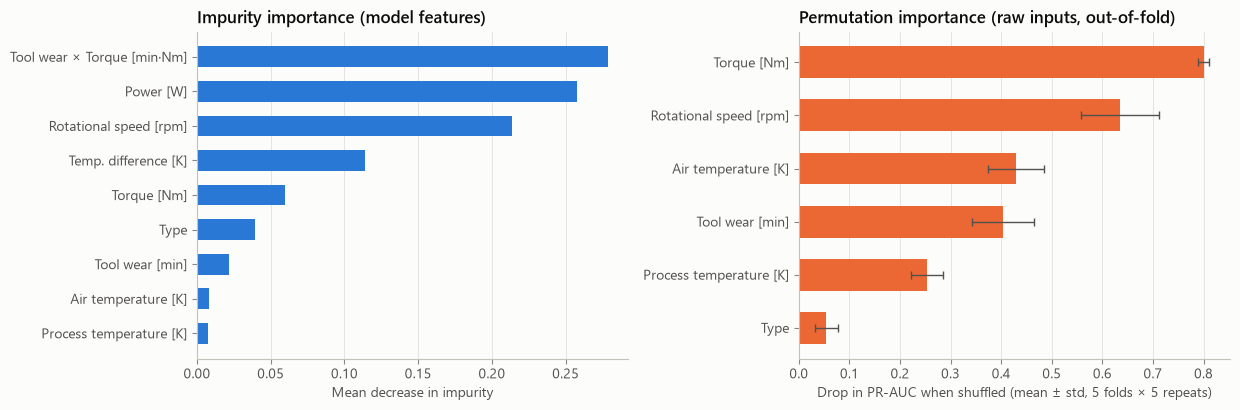

,mean,std
feature,,
Type,0.054,0.022
Process temperature [K],0.253,0.031
Tool wear [min],0.404,0.061
Air temperature [K],0.429,0.056
Rotational speed [rpm],0.635,0.077
Torque [Nm],0.800,0.012


In [2]:
rf = model.named_steps["clf"]
mdi = pd.Series(rf.feature_importances_, index=[PRETTY[f] for f in MODEL_FEATURES]).sort_values()

rng = np.random.default_rng(RANDOM_STATE)
pipe = build_pipeline(meta["model"], meta["strategy"], meta["engineered"], params=meta["hyperparameters"])
rows = []
for k, (tr, te) in enumerate(CV.split(X, y)):
    est = pipe.fit(X.iloc[tr], y.iloc[tr])
    Xte, yte = X.iloc[te], y.iloc[te]
    base_ap = average_precision_score(yte, est.predict_proba(Xte)[:, 1])
    for col in X.columns:
        for r in range(5):
            Xp = Xte.copy()
            Xp[col] = rng.permutation(Xp[col].values)
            rows.append({"fold": k, "feature": PRETTY[col],
                         "drop": base_ap - average_precision_score(yte, est.predict_proba(Xp)[:, 1])})
perm = pd.DataFrame(rows).groupby("feature")["drop"].agg(["mean", "std"]).sort_values("mean")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.2))
a1.barh(mdi.index, mdi.values, color=SERIES[0], height=0.6)
a1.set_title("Impurity importance (model features)"); a1.set_xlabel("Mean decrease in impurity"); a1.grid(axis="y", visible=False)
a2.barh(perm.index, perm["mean"], xerr=perm["std"], color=SERIES[1], height=0.6,
        error_kw=dict(ecolor=INK_2, elinewidth=1, capsize=3))
a2.set_title("Permutation importance (raw inputs, out-of-fold)"); a2.set_xlabel("Drop in PR-AUC when shuffled (mean ± std, 5 folds × 5 repeats)")
a2.grid(axis="y", visible=False)
fig.tight_layout(); savefig(fig, "12_feature_importance"); plt.show()
perm.round(3)

## 2. SHAP: global view

TreeSHAP on all 10,000 runs. The forest outputs probabilities, so SHAP values are in **probability units**:
base value + sum of a run's SHAP values = that run's P(failure). These are explanations of the final model
(trained on all data), so they describe *what the model learned*, not out-of-sample performance.

SHAP for 10,000 runs in 29s | base value (mean P) = 0.0337


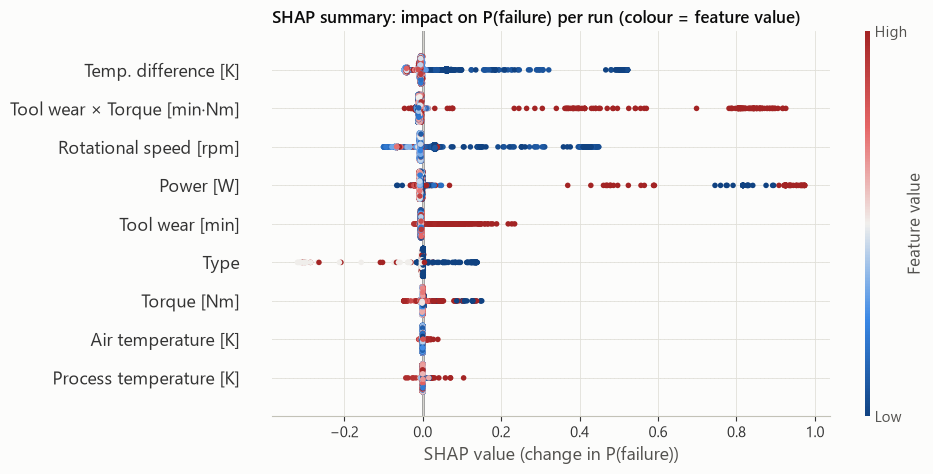

Temp. difference [K]           0.0187
Tool wear × Torque [min·Nm]    0.0178
Rotational speed [rpm]         0.0171
Power [W]                      0.0150
Tool wear [min]                0.0078
Type                           0.0032
Torque [Nm]                    0.0026
Air temperature [K]            0.0008
Process temperature [K]        0.0005
dtype: float64

In [3]:
t0 = time.time()
explainer = make_explainer(model)
sv = explain(model, X, explainer)
print(f"SHAP for {len(X):,} runs in {time.time() - t0:.0f}s | base value (mean P) = {sv.base_values[0]:.4f}")
assert np.allclose(sv.values.sum(1) + sv.base_values, model.predict_proba(X)[:, 1], atol=1e-6)  # additivity check

shap.plots.beeswarm(sv, max_display=9, color=plots.DIVERGING, show=False, plot_size=(9, 5))
fig = plt.gcf()
fig.axes[0].set_title("SHAP summary: impact on P(failure) per run (colour = feature value)", loc="left")
fig.axes[0].set_xlabel("SHAP value (change in P(failure))")
savefig(fig, "13_shap_summary"); plt.show()

mean_abs = pd.Series(np.abs(sv.values).mean(0), index=sv.feature_names).sort_values(ascending=False)
mean_abs.round(4)

**Reading the beeswarm** (and how it squares with the importance plots)
- **Temperature difference**: low values (blue) push P(failure) up by as much as +0.5. This is the heat-dissipation mode.
- **Overstrain (wear × torque)**: high values (red) push it up by as much as +0.9. This is the overstrain mode.
- **Power** is **two-sided**: both low (blue) and high (red) power give large positive values, because power failures
  occur outside a power band. A linear model cannot express this U-shape, which is part of why logistic regression
  lagged in notebook 02.
- **Rotational speed**: low rpm (blue) raises risk. Low speed both enables heat-dissipation failure (rule: < 1380 rpm)
  and, at a given torque band, means high power.
- **Tool wear on its own** has a moderate tail (up to about +0.2), which is the random tool-wear window above about 200 min.
- **Type**: L (blue, 0) pushes slightly up and H (red) down. Type enters only through its overstrain limit.
- Raw torque and the two raw temperatures matter little *once the physics features exist*, because those features
  absorb them. The permutation plot permutes **raw inputs**, so it credits torque (0.80 PR-AUC drop) and rpm (0.64) with
  their total effect through power and overstrain, and air temperature (0.43) with its effect through temperature
  difference. The two views agree once you account for which features each one perturbs.

## 3. SHAP: individual predictions (waterfalls)

Three runs, picked from the **out-of-fold** predictions so the selection is not flattered by in-sample fit:
a caught overstrain failure, a caught heat-dissipation failure, and a **missed** failure (OOF probability below the
alarm threshold).

In [4]:
d = df.assign(oof=oof)
cases = {
    "caught_osf": d[(d.machine_failure == 1) & (d.OSF == 1) & (d.PWF == 0) & (d.HDF == 0)].oof.idxmax(),
    "caught_hdf": d[(d.machine_failure == 1) & (d.HDF == 1) & (d.OSF == 0) & (d.PWF == 0)].oof.idxmax(),
    "missed": d[(d.machine_failure == 1)].oof.idxmin(),
}
p_in = model.predict_proba(X)[:, 1]
for name, i in cases.items():
    r = d.loc[i]
    modes = [m for m in FAILURE_MODES if r[m] == 1] or ["no mode flag"]
    print(f"{name:11s} row {i}: Type {r.type}, {r.air_temp_k} K / {r.process_temp_k} K, {r.rot_speed_rpm} rpm, "
          f"{r.torque_nm} Nm, wear {r.tool_wear_min} min | modes: {modes} | OOF P = {r.oof:.3f}, final-model P = {p_in[i]:.3f}")

caught_osf  row 160: Type L, 298.4 K / 308.2 K, 1282 rpm, 60.7 Nm, wear 216 min | modes: ['OSF'] | OOF P = 1.000, final-model P = 1.000
caught_hdf  row 4405: Type L, 302.4 K / 310.2 K, 1331 rpm, 45.5 Nm, wear 53 min | modes: ['HDF'] | OOF P = 1.000, final-model P = 0.998
missed      row 4684: Type M, 303.6 K / 311.8 K, 1421 rpm, 44.8 Nm, wear 101 min | modes: ['no mode flag'] | OOF P = 0.000, final-model P = 0.082


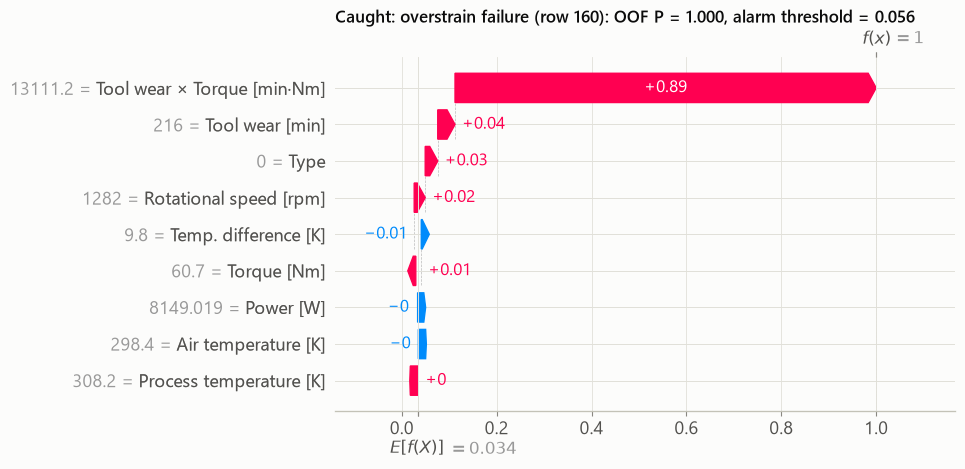

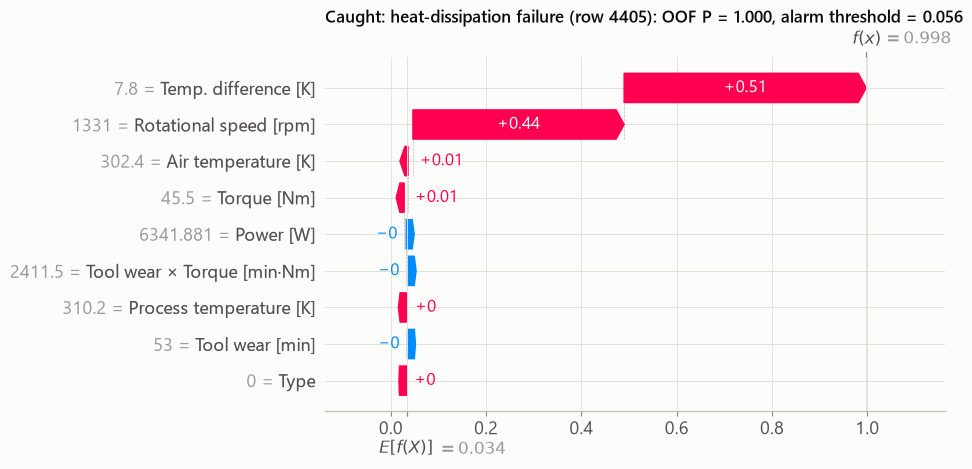

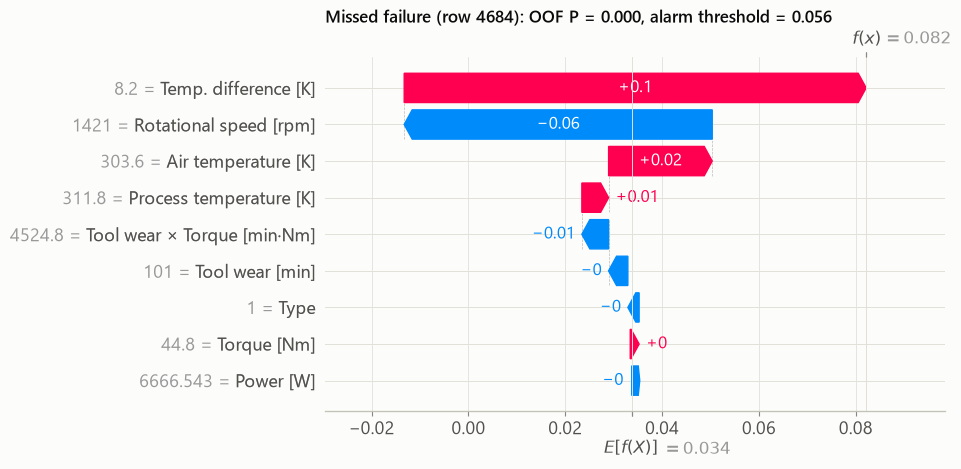

In [5]:
titles = {"caught_osf": "Caught: overstrain failure", "caught_hdf": "Caught: heat-dissipation failure",
          "missed": "Missed failure"}
for name, i in cases.items():
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    fig = plt.gcf(); fig.set_size_inches(8, 4.6)
    fig.axes[0].set_title(f"{titles[name]} (row {i}): OOF P = {oof[i]:.3f}, alarm threshold = {THRESHOLD:.3f}", loc="left")
    savefig(fig, f"14_shap_waterfall_{name}"); plt.show()

- **Overstrain case**: overstrain (wear × torque) carries almost all of the prediction. The model has learned the
  *product* limit, not just "high torque" or "high wear".
- **Heat-dissipation case**: low temperature difference *and* low rpm both push it up. Neither is alarming alone; it is
  the combination the HDF rule specifies.
- **Missed case**: this is one of the 9 failures with **no failure-mode flag** (notebook 01). Its settings are
  unremarkable: power 6.7 kW sits mid-band, tool wear is 101 min, and its temperature difference of 8.2 K is low,
  but 1,421 rpm is above the 1,380 rpm heat-dissipation limit. Models that never saw this run give it
  **P = 0.000** (out-of-fold). The waterfall shows the *final* model, which did train on it and gives 0.082: a small
  amount of memorisation, mostly attached to the low temperature difference. This is a reminder to read waterfalls of
  training rows with care, and it is why the out-of-fold number is the honest one. Failures like this are not
  explained by the process parameters, so recall cannot reach 100% on these inputs.

## 4. Partial dependence per product Type

For each raw parameter: set it to a grid value for *every* run in a 1,000-run sample (all else unchanged), average
P(failure), repeat across the grid. Done once per Type (the Type column is overwritten too). PDPs average over the
data, so they show *marginal* effects. Interactions such as wear × torque are flattened, which is why §5
looks at 2-D surfaces.

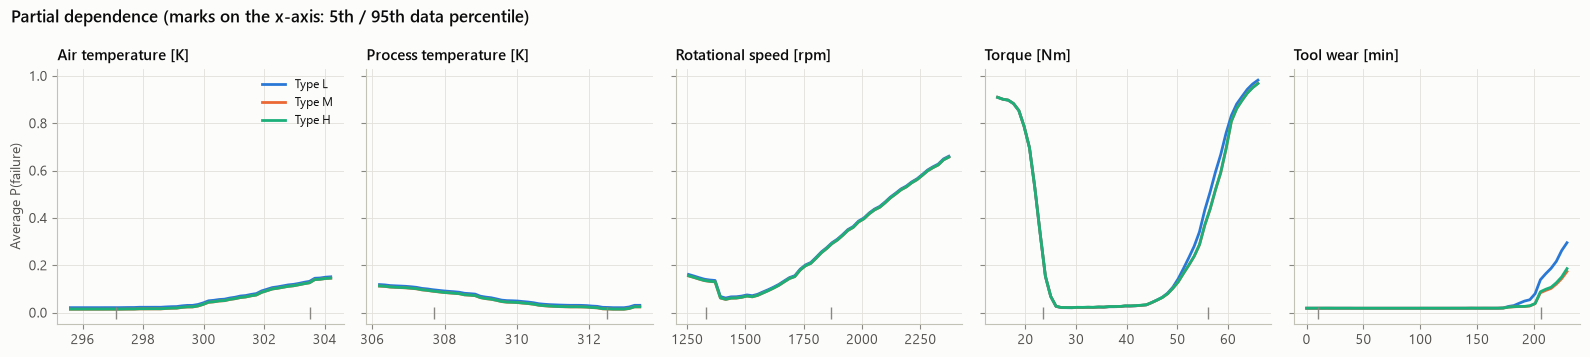

In [6]:
sample = X.sample(1000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6), sharey=True)
for ax, col in zip(axes, NUM_COLS):
    grid = np.linspace(X[col].quantile(0.005), X[col].quantile(0.995), 50)
    for k, typ in enumerate(TYPE_ORDER):
        big = pd.concat([sample.assign(**{col: v, "type": typ}) for v in grid], ignore_index=True)
        pd_ = model.predict_proba(big)[:, 1].reshape(len(grid), len(sample)).mean(1)
        ax.plot(grid, pd_, color=SERIES[k], lw=2, label=f"Type {typ}")
    ax.set_title(PRETTY[col], fontsize=10.5)
    ax.plot(X[col].quantile([0.05, 0.95]), [0, 0], "|", color=MUTED, ms=8)  # 5-95% data range marks
axes[0].set_ylabel("Average P(failure)"); axes[0].legend(fontsize=8.5)
fig.suptitle("Partial dependence (marks on the x-axis: 5th / 95th data percentile)", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(); savefig(fig, "15_partial_dependence"); plt.show()

- **Torque** shows the two-sided power band most clearly: risk rises at both ends.
- **Tool wear** is flat until about 180–200 min, then climbs, more steeply for Type L, whose overstrain limit is lowest.
  Elsewhere the three Type curves nearly coincide: Type only matters through the overstrain limit.
- **Caveat:** the steep rise with **rpm** is partly an artefact. Setting rpm to 2,300 for every run keeps each run's own
  torque (say 40 Nm), producing about 9.6 kW, a combination that never occurs in the data and violates the power band. PDPs
  assume features can be varied independently, but speed and torque are strongly linked (ρ = −0.92). This is exactly
  why §6 works in 2-D and only on data-supported settings.

## 5. Ground truth to check against: the dataset's failure-mode rules

The AI4I documentation describes how each mode is generated. We do not take that on trust; we check each rule
directly in the data (the flags are allowed here: this is *validation*, not modelling).

In [7]:
P = add_physics_features(df)
OSF_LIMIT = {"L": 11000, "M": 12000, "H": 13000}
out_band = (P.power_w < 3500) | (P.power_w > 9000)
hdf_rule = (P.temp_diff_k < 8.6) & (P.rot_speed_rpm < 1380)
checks = {
    "PWF  <=> power outside [3500, 9000] W": (out_band == (P.PWF == 1)).mean(),
    "HDF  <=> temp diff < 8.6 K AND rpm < 1380": (hdf_rule == (P.HDF == 1)).mean(),
    "OSF  <=> wear×torque > 11k (L) / 12k (M) / 13k (H)": ((P.overstrain_nm_min > P.type.map(OSF_LIMIT)) == (P.OSF == 1)).mean(),
}
for k, v in checks.items():
    print(f"{k:55s} agreement: {v:.2%}")
print(f"TWF  occurs only at tool wear {P.loc[P.TWF == 1, 'tool_wear_min'].min()}–{P.loc[P.TWF == 1, 'tool_wear_min'].max()} min; "
      f"TWF rate in 200–240 min: {P.loc[P.tool_wear_min.between(200, 240), 'TWF'].mean():.1%} (random within the window)")

PWF  <=> power outside [3500, 9000] W                   agreement: 100.00%
HDF  <=> temp diff < 8.6 K AND rpm < 1380               agreement: 100.00%
OSF  <=> wear×torque > 11k (L) / 12k (M) / 13k (H)      agreement: 100.00%
TWF  occurs only at tool wear 198–253 min; TWF rate in 200–240 min: 5.4% (random within the window)


PWF, HDF and OSF are deterministic in the data (100% agreement). TWF is random within a tool-wear window, so
it can only ever be predicted as a *rate* (about 5%) and never run by run. Next we check whether the model,
trained without any of these flags, recovered the same boundaries.

## 6. Risk surfaces over the controllable parameters

P(failure) on a 141 × 151 grid of speed × torque, for each Type at three tool-wear levels (air/process temperature
at their medians, so heat dissipation is inactive). Areas the data never covers are washed out. The orange contour is
the 1% risk budget. Dashed lines are the true power-failure boundaries (3.5 kW and 9 kW); the dotted line is the
true overstrain torque limit at that wear.

data-supported grid cells: 2,210 of 21,291 (10.4%) — speed and torque are tied together by construction (ρ = −0.92)


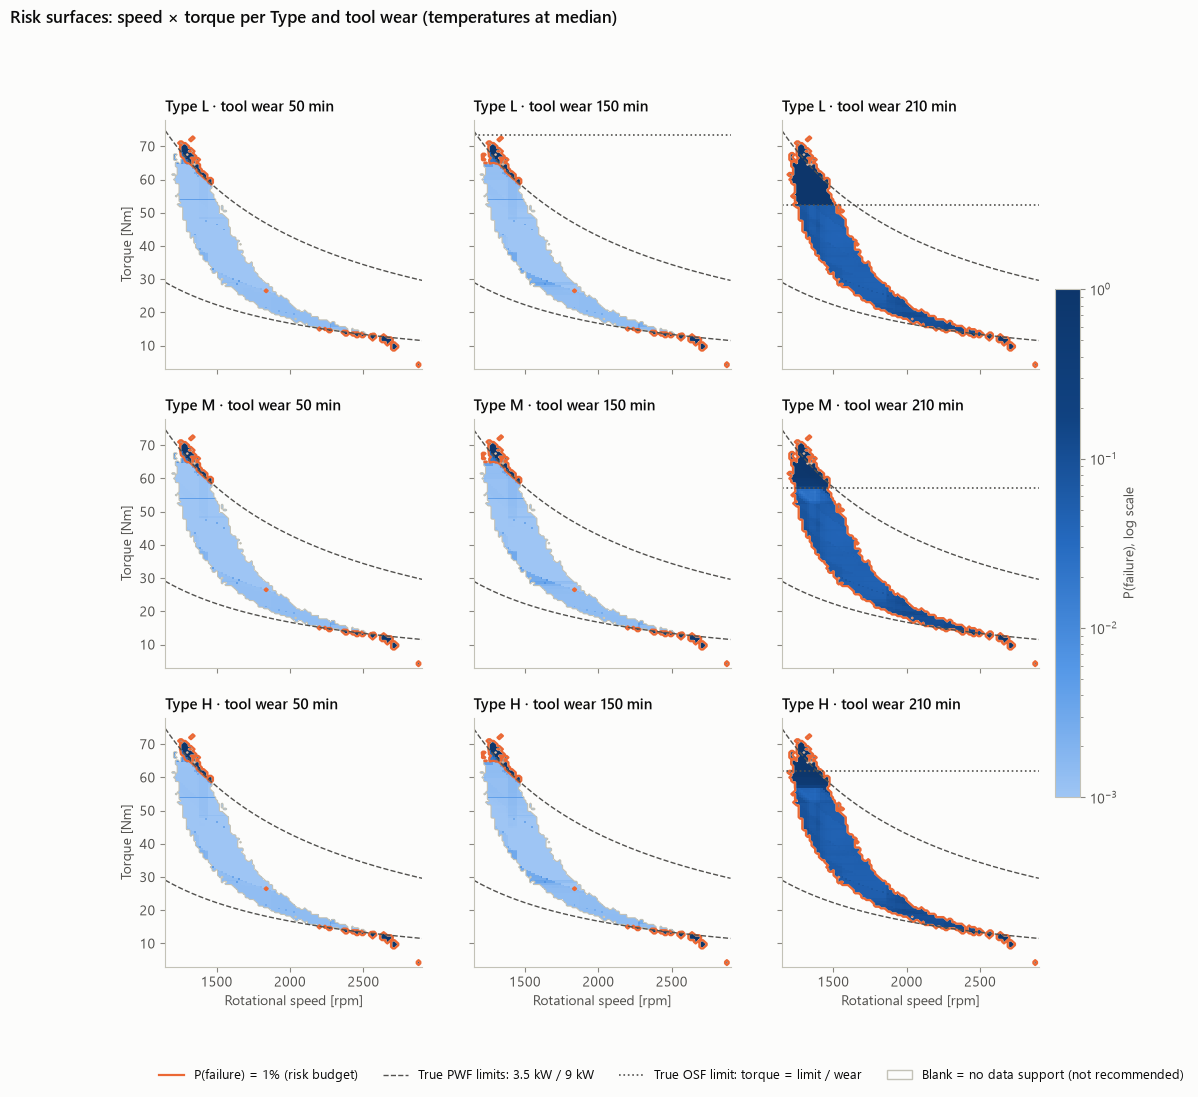

In [8]:
base = conditions(X)
support = support_mask(X)
print(f"data-supported grid cells: {support.sum():,} of {support.size:,} ({support.mean():.1%}) "
      f"— speed and torque are tied together by construction (ρ = −0.92)")

WEARS = [50, 150, 210]
norm = LogNorm(1e-3, 1)
# Ordinal-safe ramp: starts at a step that stays visible on the light surface; unsupported cells are not drawn at all
RISK_CMAP = plots.LinearSegmentedColormap.from_list("risk", ["#9ec5f4", "#5598e7", "#256abf", "#104281", "#0d366b"])
rr = np.linspace(RPM_GRID[0], RPM_GRID[-1], 300)
fig, axes = plt.subplots(3, 3, figsize=(13.5, 11), sharex=True, sharey=True)
for i, typ in enumerate(TYPE_ORDER):
    for j, w in enumerate(WEARS):
        ax = axes[i, j]
        Pg = risk_grid(model, typ, base, tool_wear_min=w)
        im = ax.pcolormesh(RPM_GRID, TORQUE_GRID, np.ma.masked_where(~support, np.clip(Pg, 1e-3, 1)),
                           norm=norm, cmap=RISK_CMAP, shading="nearest", rasterized=True)
        ax.contour(RPM_GRID, TORQUE_GRID, support.astype(float), levels=[0.5], colors=[plots.AXIS], linewidths=0.8)
        ax.contour(RPM_GRID, TORQUE_GRID, np.where(support, Pg, 0), levels=[RISK_BUDGET], colors=[C_FAIL], linewidths=1.6)
        for pw in (3500, 9000):
            ax.plot(rr, pw / (rr * np.pi / 30), ls="--", color=INK_2, lw=1)
        ax.axhline(OSF_LIMIT[typ] / w, ls=":", color=INK_2, lw=1.2)
        ax.set_xlim(1150, 2900); ax.set_ylim(TORQUE_GRID[0], TORQUE_GRID[-1]); ax.grid(False)
        ax.set_title(f"Type {typ} · tool wear {w} min", fontsize=10.5)
        if i == 2: ax.set_xlabel(PRETTY["rot_speed_rpm"])
        if j == 0: ax.set_ylabel(PRETTY["torque_nm"])
handles = [Line2D([], [], color=C_FAIL, lw=1.6, label=f"P(failure) = {RISK_BUDGET:.0%} (risk budget)"),
           Line2D([], [], color=INK_2, ls="--", lw=1, label="True PWF limits: 3.5 kW / 9 kW"),
           Line2D([], [], color=INK_2, ls=":", lw=1.2, label="True OSF limit: torque = limit / wear"),
           Patch(facecolor=plots.SURFACE, edgecolor=plots.AXIS, label="Blank = no data support (not recommended)")]
fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.005), fontsize=9)
cb = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.015); cb.set_label("P(failure), log scale")
fig.suptitle("Risk surfaces: speed × torque per Type and tool wear (temperatures at median)", x=0.01, ha="left", fontweight="semibold")
savefig(fig, "16_risk_surfaces"); plt.show()

Only data-supported settings are coloured. The band is narrow because speed and torque are tied together.
- At low and medium wear, the 1% contour cuts the band near both power limits, slightly inside the true 3.5 / 9 kW
  lines. The model is conservative at the edges.
- At 210 min, almost the whole band is above budget: that is the random tool-wear-failure window, and no speed or
  torque setting avoids it. The overstrain line (dotted) also drops into the band, more so for L than for H.

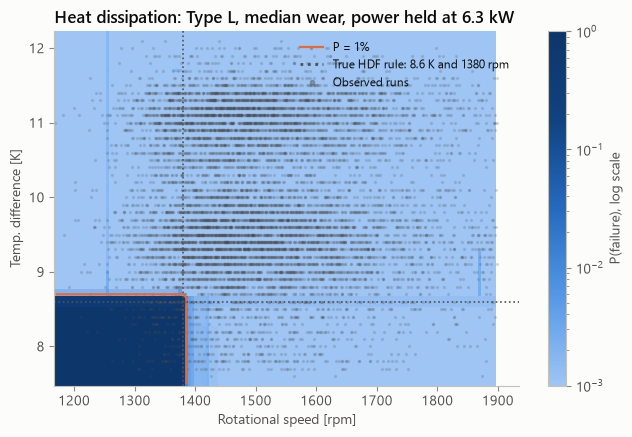

In [9]:
# Heat dissipation: temperature difference × speed. Torque is set so power stays at its median, so moving along the
# speed axis does not also cross the power-failure band; this isolates the heat-dissipation mechanism.
P_MED = float(np.median(power_w(X.rot_speed_rpm, X.torque_nm)))
td = np.linspace(7.5, 12.2, 95); rpm_h = np.arange(1170, 1900, 5)
TD, RH = np.meshgrid(td, rpm_h, indexing="ij")
cols = {**base, "tool_wear_min": base["tool_wear_min"], "process_temp_k": base["air_temp_k"] + TD.ravel(),
        "rot_speed_rpm": RH.ravel(), "torque_nm": torque_at_power(RH.ravel(), P_MED)}
Ph = predict_settings(model, "L", **cols).reshape(TD.shape)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
im = ax.pcolormesh(rpm_h, td, np.clip(Ph, 1e-3, 1), norm=norm, cmap=RISK_CMAP, shading="nearest", rasterized=True)
ax.contour(rpm_h, td, Ph, levels=[RISK_BUDGET], colors=[C_FAIL], linewidths=1.6)
ax.axhline(8.6, ls=":", color=INK_2, lw=1.2); ax.axvline(1380, ls=":", color=INK_2, lw=1.2)
obs = X.assign(td=X.process_temp_k - X.air_temp_k).query("rot_speed_rpm < 1900")
ax.scatter(obs.rot_speed_rpm, obs.td, s=2, color=INK_2, alpha=0.15, rasterized=True)
ax.set(xlabel=PRETTY["rot_speed_rpm"], ylabel=PRETTY["temp_diff_k"]); ax.grid(False)
ax.set_title(f"Heat dissipation: Type L, median wear, power held at {P_MED / 1000:.1f} kW")
ax.legend(handles=[Line2D([], [], color=C_FAIL, lw=1.6, label=f"P = {RISK_BUDGET:.0%}"),
                   Line2D([], [], color=INK_2, ls=":", label="True HDF rule: 8.6 K and 1380 rpm"),
                   Line2D([], [], marker="o", ls="", color=INK_2, alpha=0.4, ms=3, label="Observed runs")],
          loc="upper right", fontsize=8.5)
fig.colorbar(im, ax=ax, label="P(failure), log scale")
savefig(fig, "17_hdf_surface"); plt.show()

## 7. Tool wear: when to change the tool, and why the alarm threshold is not a design limit

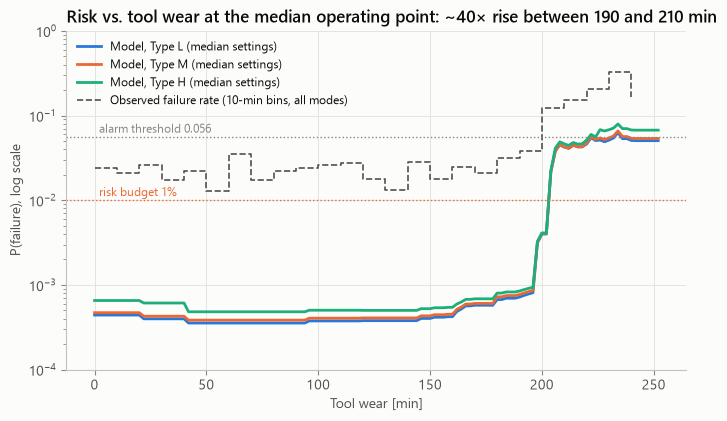

tool wear max [min]           power band [W]                            \
type                     H    L    M              H            L            M   
budget                                                                          
0.005                  202  202  202    5,250–7,750  5,250–7,750  5,250–7,750   
0.010                  202  202  202    4,750–7,750  4,750–7,750  4,750–8,000   
0.020                  202  202  202    4,500–7,750  4,500–7,750  4,500–8,250   
0.056                  220  232  220           none         none  6,750–7,500   

       torque max [Nm]              
type                 H     L     M  
budget                              
0.005             54.0  54.0  54.0  
0.010             54.0  54.0  58.5  
0.020             54.0  54.0  58.5  
0.056             53.5  44.0  54.0

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for k, typ in enumerate(TYPE_ORDER):
    _, p_w = tool_wear_limit(model, typ, base)
    ax.plot(WEAR_GRID, np.clip(p_w, 1e-4, 1), color=SERIES[k], lw=2, label=f"Model, Type {typ} (median settings)")
bins = np.arange(0, 260, 10)
emp = y.groupby(pd.cut(X.tool_wear_min, bins, right=False), observed=True).mean()
ax.step([iv.left for iv in emp.index], emp.values, where="post", color=INK_2, lw=1.2, ls="--",
        label="Observed failure rate (10-min bins, all modes)")
ax.axhline(RISK_BUDGET, color=C_FAIL, lw=1, ls=":"); ax.annotate(f"risk budget {RISK_BUDGET:.0%}", (2, RISK_BUDGET), xytext=(0, 3), textcoords="offset points", color=C_FAIL, fontsize=8.5)
ax.axhline(THRESHOLD, color=MUTED, lw=1, ls=":"); ax.annotate(f"alarm threshold {THRESHOLD:.3f}", (2, THRESHOLD), xytext=(0, 3), textcoords="offset points", color=MUTED, fontsize=8.5)
ax.set_yscale("log"); ax.set_ylim(1e-4, 1)
ax.set(xlabel=PRETTY["tool_wear_min"], ylabel="P(failure), log scale")
ax.set_title("Risk vs. tool wear at the median operating point: ~40× rise between 190 and 210 min")
ax.legend(loc="upper left", fontsize=8.5)
savefig(fig, "18_tool_wear_risk"); plt.show()

sens = []
for b in (0.005, 0.01, 0.02, THRESHOLD):
    r = operating_ranges(model, X, budget=b, support=support).set_index("type")
    sens.append(pd.DataFrame({"budget": f"{b:.3f}", "tool wear max [min]": r.tool_wear_max_min,
                              "power band [W]": [("none" if np.isnan(a) else f"{a:,.0f}–{b:,.0f}") for a, b in zip(r.power_min_w, r.power_max_w)],
                              "torque max [Nm]": r.torque_max_nm}))
pd.concat(sens).reset_index().pivot(index="budget", columns="type")

The dashed observed rate sits above the model curves at low wear because it averages over **all** settings, including
off-band power and hot days. The model curves are at the median, safe operating point. The shape is what matters:
both jump at about 200 min.

For budgets from 0.5% to 2% the recommendations barely move: change the tool before about **200 min**, and the power
band stays roughly 4.75–8 kW. Only when the *alarm threshold* is used as a design limit does the tool-wear limit
jump to 220–232 min, i.e. into the window where about 5% of runs fail at random. Barely any of the band then
qualifies ("none" = no power interval is at least half safe). This sensitivity check is what justifies separating the
two concepts.

## 8. Recommended operating ranges per Type

For each Type, at median ambient conditions:
- **Tool-wear limit**: the largest wear whose risk stays within budget at the median operating point.
- **Safe region**: grid cells that are data-supported *and* within budget at **every** wear level from 0 up to that limit.
- **Power band**: the power interval where at least half of the supported cells are safe. The safe region is
  bounded by power (speed × torque), not by speed and torque separately, so a power band is the honest way to report it.
- **Recommended set-point**: the safe cell farthest from any unsafe or unsupported cell, i.e. the most robust
  operating point.
- **Minimum speed on hot days**: if the process/air temperature difference drops to 8 K, how slow can the spindle go?

The grid search is exhaustive over a 2-D, 21k-cell space, so a stochastic optimiser such as Optuna would add
nothing here; the exhaustive search is exact on the grid and easy to audit.

In [11]:
ranges = operating_ranges(model, X, support=support)
ranges.to_csv(REPORTS_DIR / "operating_ranges.csv", index=False)
show = ranges.set_index("type")[["tool_wear_max_min", "power_min_w", "power_max_w", "rpm_min", "rpm_max",
                                 "torque_min_nm", "torque_max_nm", "min_rpm_if_temp_diff_8K",
                                 "setpoint_rpm", "setpoint_torque_nm", "setpoint_power_w"]]
show.round(1)

,tool_wear_max_min,power_min_w,power_max_w,rpm_min,rpm_max,torque_min_nm,torque_max_nm,min_rpm_if_temp_diff_8K,setpoint_rpm,setpoint_torque_nm,setpoint_power_w
type,,,,,,,,,,,
L,202,4750.0,7750.0,1237.5,1837.5,25.5,54.0,1390.0,1487.5,43.5,6776.0
M,202,4750.0,8000.0,1237.5,1837.5,25.5,58.5,1390.0,1500.0,42.5,6675.9
H,202,4750.0,7750.0,1237.5,1837.5,25.5,54.0,1390.0,1500.0,42.5,6675.9


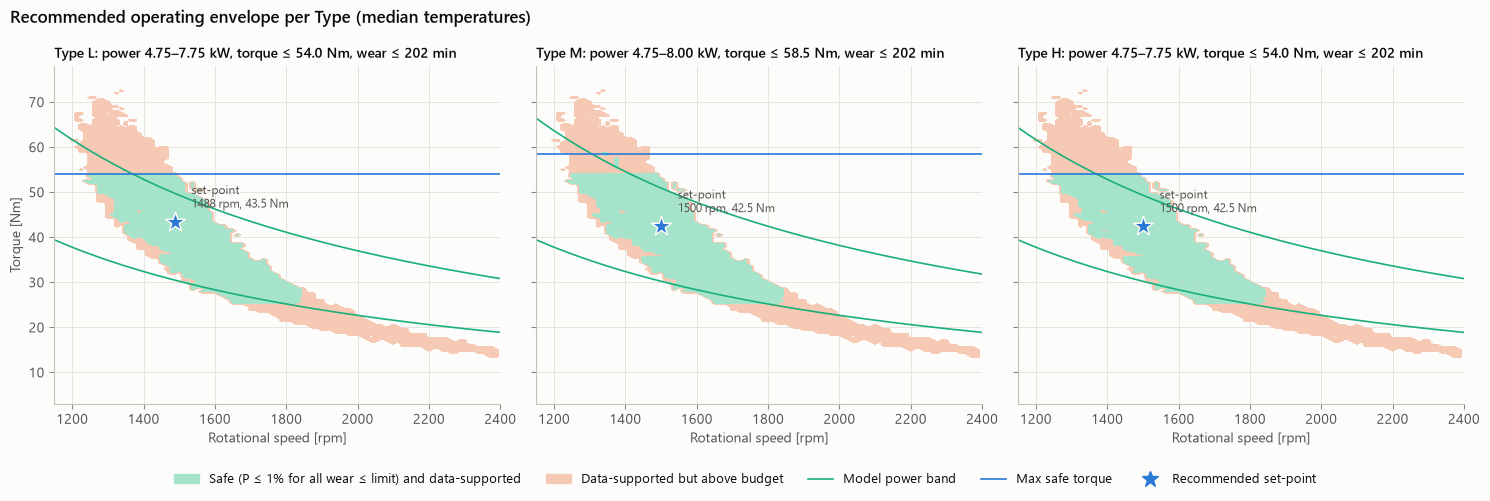

In [12]:
# Recommendation map: safe region at the tool-wear limit, set-point, model power band
R, T = np.meshgrid(RPM_GRID, TORQUE_GRID)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, (_, r) in zip(axes, ranges.iterrows()):
    safe = safe_region(model, r.type, base, support, r.tool_wear_max_min)
    state = np.where(safe, 2, np.where(support, 1, 0)).astype(float)
    ax.contourf(RPM_GRID, TORQUE_GRID, state, levels=[0.5, 1.5, 2.5], colors=["#f6c9b4", "#a6e3cb"])
    for pw, ls in ((r.power_min_w, "-"), (r.power_max_w, "-")):
        ax.plot(rr, pw / (rr * np.pi / 30), color=SERIES[2], lw=1.2, ls=ls)
    ax.axhline(r.torque_max_nm, color=SERIES[0], lw=1.2)
    ax.scatter([r.setpoint_rpm], [r.setpoint_torque_nm], marker="*", s=220, color=SERIES[0], edgecolor=plots.SURFACE, zorder=5)
    ax.annotate(f"set-point\n{r.setpoint_rpm:.0f} rpm, {r.setpoint_torque_nm:.1f} Nm", (r.setpoint_rpm, r.setpoint_torque_nm),
                xytext=(12, 10), textcoords="offset points", fontsize=8.5, color=INK_2)
    ax.set(xlim=(1150, 2400), ylim=(3, 78), xlabel=PRETTY["rot_speed_rpm"])
    ax.set_title(f"Type {r.type}: power {r.power_min_w/1000:.2f}–{r.power_max_w/1000:.2f} kW, torque ≤ {r.torque_max_nm:.1f} Nm, "
                 f"wear ≤ {r.tool_wear_max_min} min", fontsize=10)
axes[0].set_ylabel(PRETTY["torque_nm"])
fig.legend(handles=[Patch(color="#a6e3cb", label=f"Safe (P ≤ {RISK_BUDGET:.0%} for all wear ≤ limit) and data-supported"),
                    Patch(color="#f6c9b4", label="Data-supported but above budget"),
                    Line2D([], [], color=SERIES[2], lw=1.2, label="Model power band"),
                    Line2D([], [], color=SERIES[0], lw=1.2, label="Max safe torque"),
                    Line2D([], [], marker="*", ls="", color=SERIES[0], ms=12, label="Recommended set-point")],
           loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.08), fontsize=9)
fig.suptitle("Recommended operating envelope per Type (median temperatures)", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(); savefig(fig, "19_operating_ranges"); plt.show()

## 9. Do the recommendations agree with the physics?

In [13]:
rg = ranges.set_index("type")
val = pd.DataFrame([
    {"constraint": "Power band (PWF)", "model": f"{rg.power_min_w.min():,.0f}–{rg.power_max_w.max():,.0f} W",
     "dataset rule": "3,500–9,000 W", "verdict": "inside the true band (conservative)"},
    {"constraint": "Tool wear (TWF)", "model": f"≤ {rg.tool_wear_max_min.min()} min",
     "dataset rule": "random failures at 198–253 min", "verdict": "stops at the start of the window"},
    {"constraint": "Min speed when ΔT ≈ 8 K (HDF)", "model": f"≥ {rg.min_rpm_if_temp_diff_8K.min():.0f} rpm",
     "dataset rule": "≥ 1,380 rpm when ΔT < 8.6 K", "verdict": "matches"},
    *[{"constraint": f"Torque × wear, Type {t} (OSF)",
       "model": f"≤ {rg.loc[t, 'torque_x_wear_max']:,.0f} min·Nm",
       "dataset rule": f"≤ {OSF_LIMIT[t]:,} min·Nm",
       "verdict": "matches" if rg.loc[t, 'torque_x_wear_max'] > 0.9 * OSF_LIMIT[t] else "more conservative than the rule"}
      for t in TYPE_ORDER],
])
val

,constraint,model,dataset rule,verdict
0,Power band (PWF),"4,750–8,000 W","3,500–9,000 W",inside the true band (conservative)
1,Tool wear (TWF),≤ 202 min,random failures at 198–253 min,stops at the start of the window
2,Min speed when ΔT ≈ 8 K (HDF),≥ 1390 rpm,"≥ 1,380 rpm when ΔT < 8.6 K",matches
3,"Torque × wear, Type L (OSF)","≤ 10,908 min·Nm","≤ 11,000 min·Nm",matches
4,"Torque × wear, Type M (OSF)","≤ 11,817 min·Nm","≤ 12,000 min·Nm",matches
5,"Torque × wear, Type H (OSF)","≤ 10,908 min·Nm","≤ 13,000 min·Nm",more conservative than the rule


In [14]:
# Why is Type H's torque cap conservative? Count the evidence the model had near H's true limit.
hi = (X.tool_wear_min >= 150) & (X.torque_nm >= 55)
print("runs with wear >= 150 min and torque >= 55 Nm, by Type:", X[hi].type.value_counts().reindex(TYPE_ORDER).to_dict())
print("…of which failed:", y[hi].groupby(X[hi].type).sum().reindex(TYPE_ORDER).to_dict())

runs with wear >= 150 min and torque >= 55 Nm, by Type: {'L': 115, 'M': 51, 'H': 12}
…of which failed: {'L': 62, 'M': 11, 'H': 3}


Without ever seeing the failure-mode flags, the model recovered the power band, the heat-dissipation speed limit,
the tool-wear window and the L/M overstrain limits, each to within a few percent. Where it deviates, it errs on the
**safe side**:
- The power band is about 1 kW narrower than the rule at each end. Few runs sit near those edges, and forest
  probabilities blur sharp boundaries.
- Type H's torque cap is below its true 13k overstrain limit. Type H is only 10% of the data, and high-wear,
  high-torque H runs are rare (counts above), so the model has little evidence that H tolerates more strain.
  It behaves as if H were L/M. This is a data limitation, worth stating rather than hiding.

## 10. Failure-mode classifiers (for the dashboard)

The dashboard reports the *most likely failure mode* for a setting, which needs a separate model per mode.
These are one-vs-rest classifiers predicting each mode flag from the same inputs, using the same pipeline and
hyper-parameters as the main model. The mode flags are **targets** here, never features, so nothing leaks.

In [15]:
mode_models, mode_cv = {}, []
for mode in FAILURE_MODES:
    ym = df[mode].astype(int)
    pipe_m = build_pipeline(meta["model"], meta["strategy"], meta["engineered"], params=meta["hyperparameters"])
    r = run_cv(pipe_m, X, ym)
    mode_cv.append({"mode": mode, "name": FAILURE_MODE_NAMES[mode], "positives": int(ym.sum()),
                    "chance PR-AUC": ym.mean(), "PR-AUC": f"{r.folds.pr_auc.mean():.3f} ± {r.folds.pr_auc.std():.3f}",
                    "ROC-AUC": f"{r.folds.roc_auc.mean():.3f} ± {r.folds.roc_auc.std():.3f}"})
    mode_models[mode] = pipe_m.fit(X, ym)
joblib.dump(mode_models, MODELS_DIR / "mode_models.joblib", compress=3)
mode_cv = pd.DataFrame(mode_cv).set_index("mode")
mode_cv.to_csv(REPORTS_DIR / "mode_model_cv.csv")
mode_cv.round(4)

,name,positives,chance PR-AUC,PR-AUC,ROC-AUC
mode,,,,,
TWF,Tool wear failure,46,0.0046,0.095 ± 0.033,0.967 ± 0.012
HDF,Heat dissipation failure,115,0.0115,0.994 ± 0.008,1.000 ± 0.000
PWF,Power failure,95,0.0095,1.000 ± 0.000,1.000 ± 0.000
OSF,Overstrain failure,98,0.0098,0.998 ± 0.005,1.000 ± 0.000
RNF,Random failure,19,0.0019,0.011 ± 0.013,0.542 ± 0.114


The deterministic modes (PWF, HDF, OSF) are predictable. TWF is only weakly predictable, because it is random
within the tool-wear window, and RNF is close to chance, as it should be. The dashboard shows the mode probabilities
side by side, so a user sees when "most likely mode" is a weak call.

## 11. Summary

**What drives failure?** Power (two-sided: both too low and too high), overstrain (tool wear × torque), temperature
difference and speed. Tool wear on its own matters only past about 200 min. As raw inputs, torque and speed carry the
most out-of-fold signal (PR-AUC drops of 0.80 and 0.64 when shuffled).

**Recommended operating envelope** (median ambient temperatures; P(failure) ≤ 1% at every tool wear up to the limit;
data-supported settings only):

| Type | Change tool before | Power band | Max torque | Min speed if ΔT ≈ 8 K | Robust set-point |
|---|---|---|---|---|---|
| L | 202 min | 4.75–7.75 kW | 54.0 Nm | 1,390 rpm | 1,488 rpm · 43.5 Nm (6.8 kW) |
| M | 202 min | 4.75–8.00 kW | 58.5 Nm | 1,390 rpm | 1,500 rpm · 42.5 Nm (6.7 kW) |
| H | 202 min | 4.75–7.75 kW | 54.0 Nm | 1,390 rpm | 1,500 rpm · 42.5 Nm (6.7 kW) |

**Checked against the physics:** trained without any failure-mode flags, the model recovered the power band (inside the
true 3.5–9 kW, about 1 kW conservative at each end), the heat-dissipation speed limit (1,390 vs 1,380 rpm), the
tool-wear window (stops at 202, where random tool failures begin at 198) and the L/M overstrain limits (10.9k / 11.8k vs
11k / 12k min·Nm). Type H's overstrain limit is under-estimated (10.9k vs 13k) because only 12 H runs combine high wear
and high torque. That is a data limitation, and it errs on the safe side.

**Design choice worth defending:** the operating envelope uses a 1% *risk budget*, not the 0.056 *alarm threshold*.
The threshold answers "flag this run?" and sits on the ~5% random tool-wear plateau. Used as a design limit, it would
accept 220–232 min of tool wear. Budgets between 0.5% and 2% give the same recommendations.

**Limitations**
- AI4I 2020 is **synthetic**: its failure modes are simple rules. That is what makes the physics check possible, but
  real machines will be noisier.
- Ranges hold the non-varied parameters at their medians. Use the dashboard's risk map to explore other conditions.
- SHAP explanations describe the final model, which trained on all rows. Per-row explanations of training rows can
  reflect memorisation (see the missed case), so out-of-fold probabilities are the honest per-run numbers.
- Random (RNF) and unlabelled failures, plus the run-by-run timing of tool-wear failures, are not predictable from these
  inputs. This caps recall.